In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Project root
PROJECT_ROOT = Path.cwd().parent

# Load processed daily sales data
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "daily_sales.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

# Sort dates
df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDate range:", df["Date"].min(), "to", df["Date"].max())
print("\nMissing values:\n", df.isnull().sum())

display(df.head())

Dataset shape: (739, 5)

Columns: ['Date', 'Total_Quantity', 'Total_Revenue', 'Total_Invoices', 'Revenue_Spike_Flag']

Date range: 2009-12-01 00:00:00 to 2011-12-09 00:00:00

Missing values:
 Date                  0
Total_Quantity        0
Total_Revenue         0
Total_Invoices        0
Revenue_Spike_Flag    0
dtype: int64


,Date,Total_Quantity,Total_Revenue,Total_Invoices,Revenue_Spike_Flag
0,2009-12-01,26098.0,54351.23,119.0,False
1,2009-12-02,31804.0,63172.58,115.0,False
2,2009-12-03,49221.0,73972.45,124.0,False
3,2009-12-04,21210.0,40582.32,89.0,False
4,2009-12-05,5119.0,9803.05,30.0,False


In [2]:

# Forecast target
target = "Total_Revenue"

# Keep only date and target
forecast_df = df[["Date", target]].copy()
forecast_df = forecast_df.sort_values("Date").reset_index(drop=True)

# Last 30 days for testing; earlier dates for training
test_days = 30

train_df = forecast_df.iloc[:-test_days].copy()
test_df = forecast_df.iloc[-test_days:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

print("\nTraining revenue mean:", round(train_df[target].mean(), 2))
print("Testing revenue mean:", round(test_df[target].mean(), 2))


Training rows: 709
Testing rows: 30

Training period:
2009-12-01 00:00:00 to 2011-11-09 00:00:00

Testing period:
2011-11-10 00:00:00 to 2011-12-09 00:00:00

Training revenue mean: 26498.47
Testing revenue mean: 56307.24


In [3]:

# Baseline: predict every test day using the last training day's revenue
last_train_revenue = train_df["Total_Revenue"].iloc[-1]

test_df = test_df.copy()
test_df["Naive_Forecast"] = last_train_revenue

print("Last training day revenue:", round(last_train_revenue, 2))
print("\nBaseline predictions:")
display(test_df.head())

print("\nActual test revenue mean:",
      round(test_df["Total_Revenue"].mean(), 2))

print("Naive forecast value:",
      round(test_df["Naive_Forecast"].mean(), 2))


Last training day revenue: 65879.97

Baseline predictions:


,Date,Total_Revenue,Naive_Forecast
709,2011-11-10,70868.00,65879.97
710,2011-11-11,55107.87,65879.97
711,2011-11-12,0.00,65879.97
712,2011-11-13,33878.15,65879.97
713,2011-11-14,114237.40,65879.97



Actual test revenue mean: 56307.24
Naive forecast value: 65879.97


In [5]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = test_df["Total_Revenue"]
y_pred = test_df["Naive_Forecast"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE is calculated only where actual revenue is non-zero.
nonzero_mask = y_true != 0
mape = (
    np.mean(
        np.abs(
            (y_true[nonzero_mask] - y_pred[nonzero_mask])
            / y_true[nonzero_mask]
        )
    ) * 100
)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE (non-zero actual days only): {mape:.2f}%")
print("Zero-revenue test days:", int((y_true == 0).sum()))


MAE:  26741.02
RMSE: 39349.33
MAPE (non-zero actual days only): 39.41%
Zero-revenue test days: 4


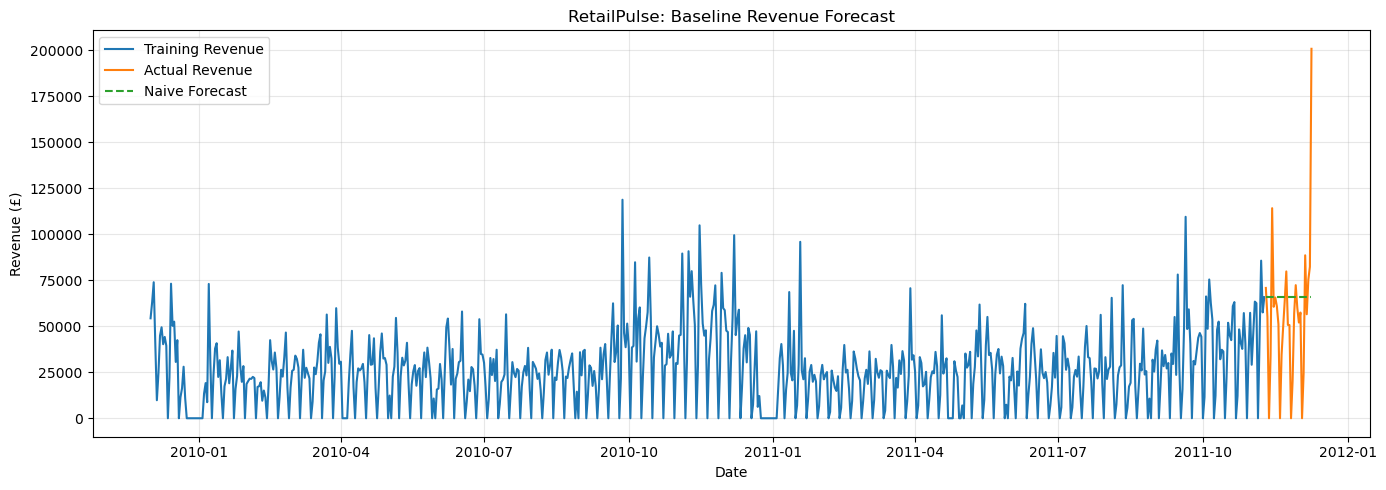

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    train_df["Date"],
    train_df["Total_Revenue"],
    label="Training Revenue"
)

plt.plot(
    test_df["Date"],
    test_df["Total_Revenue"],
    label="Actual Revenue"
)

plt.plot(
    test_df["Date"],
    test_df["Naive_Forecast"],
    label="Naive Forecast",
    linestyle="--"
)

plt.title("RetailPulse: Baseline Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

DayOfWeek
Monday       34113.978533
Tuesday      38473.112849
Wednesday    32909.852198
Thursday     39577.478887
Friday       31357.630972
Saturday        93.362381
Sunday       17134.736019
Name: Total_Revenue, dtype: float64


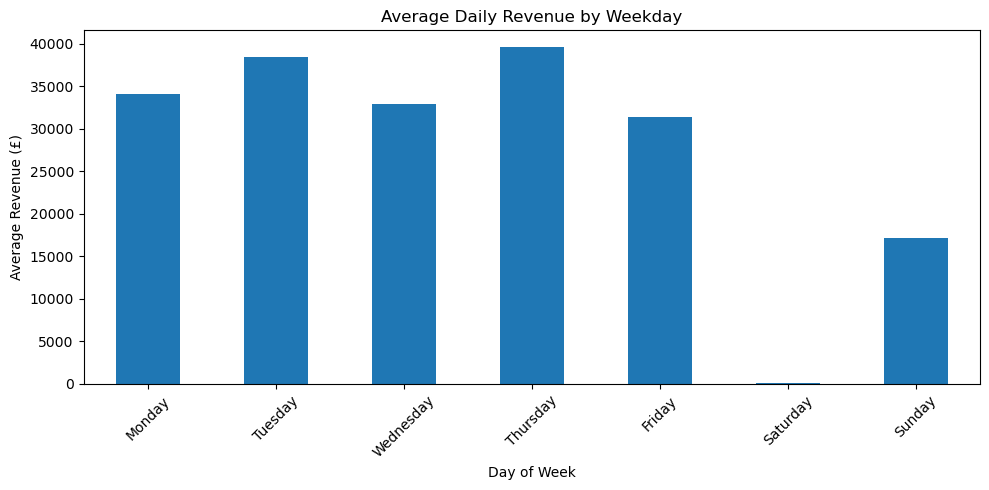

In [7]:
# Add weekday information
weekday_df = df.copy()
weekday_df["DayOfWeek"] = weekday_df["Date"].dt.day_name()

# Average revenue by weekday
weekday_revenue = (
    weekday_df.groupby("DayOfWeek")["Total_Revenue"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

print(weekday_revenue)

weekday_revenue.plot(kind="bar", figsize=(10, 5))
plt.title("Average Daily Revenue by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Prepare data for Prophet
prophet_df = df[["Date", "Total_Revenue"]].copy()

prophet_df = prophet_df.rename(
    columns={
        "Date": "ds",
        "Total_Revenue": "y"
    }
)

# Keep only training period to avoid data leakage
prophet_train = prophet_df.iloc[:-30].copy()

print("Prophet training shape:", prophet_train.shape)
print("Columns:", prophet_train.columns.tolist())
print("Start date:", prophet_train["ds"].min())
print("End date:", prophet_train["ds"].max())
print("Missing values:")
print(prophet_train.isnull().sum())
print(prophet_train.head())

Prophet training shape: (709, 2)
Columns: ['ds', 'y']
Start date: 2009-12-01 00:00:00
End date: 2011-11-09 00:00:00
Missing values:
ds    0
y     0
dtype: int64
          ds         y
0 2009-12-01  54351.23
1 2009-12-02  63172.58
2 2009-12-03  73972.45
3 2009-12-04  40582.32
4 2009-12-05   9803.05


In [9]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   --- ------------------------------------ 1.0/12.1 MB 6.3 MB/s eta 0:00:02
   ----- ---------------------------------- 1.6/12.1 MB 4.9 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/12.1 MB 2.9 MB/s eta 0:00:04
   --------- ------------------------------ 2.9/12.1 MB 3.6 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/12.1 MB 3.6 MB/s eta 0:00:03
   -------------- ------------------------- 4.5/12.1 MB 3.7 MB/s eta 0:00:03
   ----------------- ---------------------- 5.2/12.1 MB 3.8 MB/s eta 0:00:02
   ------------------- -------------------- 6.0/12.1 MB 3.8 MB/s eta 0:00:02
   ---------------------- ----------------- 6.8/12.1 MB 3.7 MB/s eta 0:00:02
   ------------------------- -------------- 7.9/12.1 MB 3.8 MB/s eta 0:00:02
   ---------------------------- ----------- 8.7/12.1 MB 3.8 MB/s eta 0:00:01
   ------------------------------- -------- 9.4/12.1 MB 3.8 MB/s eta 0:00:01
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [10]:
import prophet

print("Prophet version:", prophet.__version__)
print("Prophet imported successfully!")

Importing plotly failed. Interactive plots will not work.


Prophet version: 1.5.0
Prophet imported successfully!


In [11]:
from prophet import Prophet

# Create Prophet model
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

# Train model using training data only
prophet_model.fit(prophet_train)

print("Prophet model trained successfully!")

c:\Users\mukes\.conda\envs\mlproj\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:56:55 - cmdstanpy - INFO - Chain [1] start processing
12:56:55 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [12]:
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet model retrained successfully!")

12:57:14 - cmdstanpy - INFO - Chain [1] start processing
12:57:15 - cmdstanpy - INFO - Chain [1] done processing


Prophet model retrained successfully!


In [13]:
# Create future dates for the 30-day test period
future = prophet_model.make_future_dataframe(
    periods=30,
    freq="D"
)

# Generate predictions
forecast = prophet_model.predict(future)

# Keep predictions for the test period only
prophet_test_forecast = forecast[
    forecast["ds"].isin(test_df["Date"])
][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()

# Rename columns for clarity
prophet_test_forecast = prophet_test_forecast.rename(
    columns={
        "ds": "Date",
        "yhat": "Prophet_Forecast",
        "yhat_lower": "Lower_Bound",
        "yhat_upper": "Upper_Bound"
    }
)

print("Forecast shape:", prophet_test_forecast.shape)
print(prophet_test_forecast.head())

Forecast shape: (30, 4)
          Date  Prophet_Forecast   Lower_Bound   Upper_Bound
709 2011-11-10      47680.012761  29725.480818  66362.118673
710 2011-11-11      38124.840657  18520.048412  55250.875433
711 2011-11-12       9454.907375 -10146.437683  27698.531718
712 2011-11-13      26115.777651   8393.100167  44835.137951
713 2011-11-14      41887.592856  23447.021191  60014.867417


In [14]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Match actual revenue with Prophet predictions by date
comparison_df = test_df[["Date", "Total_Revenue", "Naive_Forecast"]].merge(
    prophet_test_forecast[["Date", "Prophet_Forecast"]],
    on="Date",
    how="inner"
)

y_true = comparison_df["Total_Revenue"]
y_prophet = comparison_df["Prophet_Forecast"]

# Prophet metrics
prophet_mae = mean_absolute_error(y_true, y_prophet)
prophet_rmse = np.sqrt(mean_squared_error(y_true, y_prophet))

# MAPE excluding zero-revenue days
nonzero_mask = y_true != 0
prophet_mape = (
    np.mean(
        np.abs(
            (y_true[nonzero_mask] - y_prophet[nonzero_mask])
            / y_true[nonzero_mask]
        )
    ) * 100
)

# Baseline metrics for comparison
baseline_mae = mean_absolute_error(
    y_true, comparison_df["Naive_Forecast"]
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_true, comparison_df["Naive_Forecast"])
)

baseline_mape = (
    np.mean(
        np.abs(
            (y_true[nonzero_mask] -
             comparison_df.loc[nonzero_mask, "Naive_Forecast"])
            / y_true[nonzero_mask]
        )
    ) * 100
)

print("BASELINE vs PROPHET")
print("-" * 35)
print(f"Baseline MAE:  £{baseline_mae:.2f}")
print(f"Prophet MAE:   £{prophet_mae:.2f}")
print(f"Baseline RMSE: £{baseline_rmse:.2f}")
print(f"Prophet RMSE:  £{prophet_rmse:.2f}")
print(f"Baseline MAPE: {baseline_mape:.2f}%")
print(f"Prophet MAPE:  {prophet_mape:.2f}%")
print("Compared test days:", len(comparison_df))

BASELINE vs PROPHET
-----------------------------------
Baseline MAE:  £26741.02
Prophet MAE:   £22482.11
Baseline RMSE: £39349.33
Prophet RMSE:  £37077.52
Baseline MAPE: 39.41%
Prophet MAPE:  30.49%
Compared test days: 30


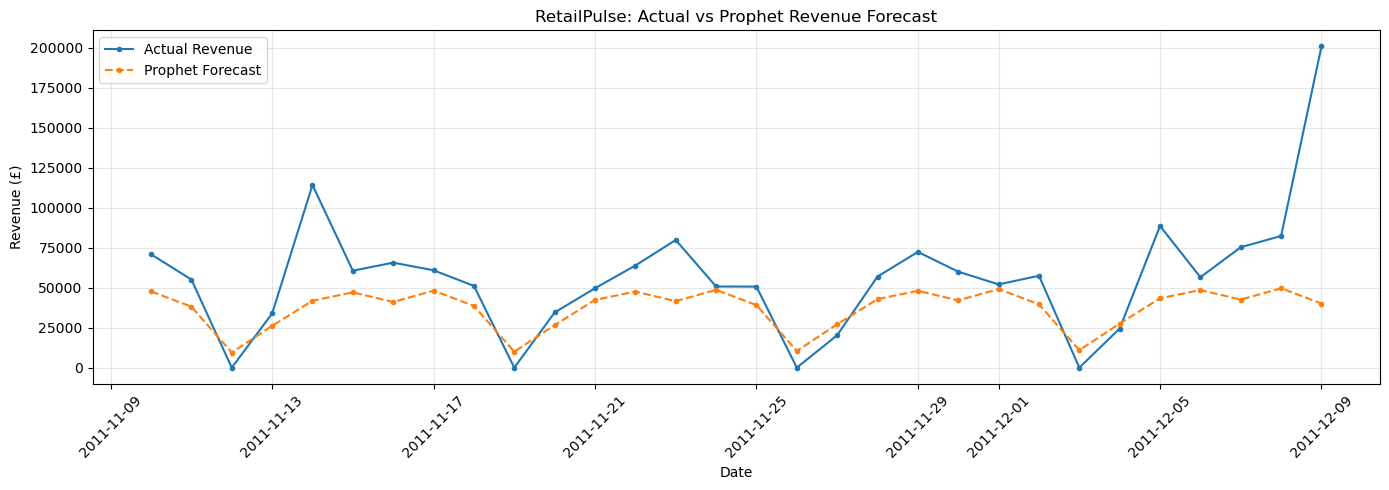

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparison_df["Date"],
    comparison_df["Total_Revenue"],
    label="Actual Revenue",
    marker="o",
    markersize=3
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Prophet_Forecast"],
    label="Prophet Forecast",
    linestyle="--",
    marker="o",
    markersize=3
)

plt.title("RetailPulse: Actual vs Prophet Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Calculate prediction errors
comparison_df["Prophet_Error"] = (
    comparison_df["Total_Revenue"]
    - comparison_df["Prophet_Forecast"]
)

comparison_df["Absolute_Error"] = (
    comparison_df["Prophet_Error"].abs()
)

# Show days with the largest errors
largest_errors = comparison_df.sort_values(
    "Absolute_Error",
    ascending=False
)

print(
    largest_errors[
        ["Date", "Total_Revenue", "Prophet_Forecast",
         "Prophet_Error", "Absolute_Error"]
    ].head(10).to_string(index=False)
)

      Date  Total_Revenue  Prophet_Forecast  Prophet_Error  Absolute_Error
2011-12-09      200918.98      40099.385381  160819.594619   160819.594619
2011-11-14      114237.40      41887.592856   72349.807144    72349.807144
2011-12-05       88620.84      43368.501399   45252.338601    45252.338601
2011-11-23       79847.00      41574.174046   38272.825954    38272.825954
2011-12-07       75315.55      42561.446408   32754.103592    32754.103592
2011-12-08       82371.55      49654.557484   32716.992516    32716.992516
2011-11-16       65672.53      41080.537865   24591.992135    24591.992135
2011-11-29       72384.82      48072.583852   24312.236148    24312.236148
2011-11-10       70868.00      47680.012761   23187.987239    23187.987239
2011-11-30       60025.57      42067.810227   17957.759773    17957.759773


In [17]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save actual revenue and model predictions
comparison_df.to_csv(
    REPORTS_DIR / "prophet_forecast_results.csv",
    index=False
)

# Save model evaluation summary
metrics_df = pd.DataFrame({
    "Model": ["Naive Baseline", "Prophet"],
    "MAE": [baseline_mae, prophet_mae],
    "RMSE": [baseline_rmse, prophet_rmse],
    "MAPE_percent": [baseline_mape, prophet_mape]
})

metrics_df.to_csv(
    REPORTS_DIR / "forecast_metrics.csv",
    index=False
)

print(metrics_df.to_string(index=False))
print("\nForecast results saved to:", REPORTS_DIR)

         Model          MAE         RMSE  MAPE_percent
Naive Baseline 26741.022667 39349.326705     39.414582
       Prophet 22482.109350 37077.517911     30.486119

Forecast results saved to: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\reports


In [18]:
import torch
import numpy as np
import pandas as pd

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.10.0+cpu
CUDA available: False
Running on CPU


In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Use daily revenue data
lstm_df = df[["Date", "Total_Revenue"]].copy()
lstm_df = lstm_df.sort_values("Date").reset_index(drop=True)

# Keep the same chronological train/test split
train_values = lstm_df["Total_Revenue"].iloc[:-30].to_numpy()
test_values = lstm_df["Total_Revenue"].iloc[-30:].to_numpy()

# Fit scaler on training data only
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(
    train_values.reshape(-1, 1)
).flatten()

# Scale test data using the training scaler
test_scaled = scaler.transform(
    test_values.reshape(-1, 1)
).flatten()

print("Training observations:", len(train_scaled))
print("Testing observations:", len(test_scaled))
print("Scaled training min:", round(train_scaled.min(), 4))
print("Scaled training max:", round(train_scaled.max(), 4))
print("Data preparation completed!")

Training observations: 709
Testing observations: 30
Scaled training min: 0.0
Scaled training max: 1.0
Data preparation completed!


In [20]:
import numpy as np

LOOKBACK = 30

# Create sequences from training data
X_train, y_train = [], []

for i in range(LOOKBACK, len(train_scaled)):
    X_train.append(train_scaled[i - LOOKBACK:i])
    y_train.append(train_scaled[i])

X_train = np.array(X_train)
y_train = np.array(y_train)

# LSTM input shape: (samples, time steps, features)
X_train = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Lookback days:", LOOKBACK)

X_train shape: (679, 30, 1)
y_train shape: (679,)
Lookback days: 30


In [21]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducible results
torch.manual_seed(42)
np.random.seed(42)

# Convert NumPy arrays to PyTorch tensors
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

train_dataset = TensorDataset(X_tensor, y_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)

# Define LSTM model
class RevenueLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            num_layers=1,
            batch_first=True
        )
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        return self.fc(last_output)

lstm_model = RevenueLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

# Train model
epochs = 30

for epoch in range(epochs):
    lstm_model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = lstm_model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(train_dataset)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.6f}")

print("LSTM training completed!")

Epoch 5/30, Loss: 0.026487
Epoch 10/30, Loss: 0.025981
Epoch 15/30, Loss: 0.025436
Epoch 20/30, Loss: 0.024647
Epoch 25/30, Loss: 0.024386
Epoch 30/30, Loss: 0.023955
LSTM training completed!


In [22]:
# Prepare the last 30 training days as the initial input
history = list(train_scaled[-LOOKBACK:])

lstm_predictions_scaled = []

lstm_model.eval()

with torch.no_grad():
    for _ in range(30):
        # Shape: (1 sample, 30 days, 1 feature)
        x_input = torch.tensor(
            history[-LOOKBACK:],
            dtype=torch.float32
        ).reshape(1, LOOKBACK, 1)

        # Predict next day
        next_pred = lstm_model(x_input).item()
        lstm_predictions_scaled.append(next_pred)

        # Use prediction to forecast the following day
        history.append(next_pred)

# Convert predictions back to original revenue scale
lstm_predictions = scaler.inverse_transform(
    np.array(lstm_predictions_scaled).reshape(-1, 1)
).flatten()

print("LSTM predictions:", len(lstm_predictions))
print("First 5 predictions:")
print(np.round(lstm_predictions[:5], 2))

LSTM predictions: 30
First 5 predictions:
[41807.27 39813.03 39147.62 38720.39 38266.46]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual revenue for the same 30 test days
y_true = test_df["Total_Revenue"].to_numpy()

# Calculate metrics consistently
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0
    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )
    ) * 100

    return mae, rmse, mape

# Evaluate all three models
baseline_pred = test_df["Naive_Forecast"].to_numpy()
prophet_pred = prophet_test_forecast["Prophet_Forecast"].to_numpy()

baseline_metrics = evaluate_model(y_true, baseline_pred)
prophet_metrics = evaluate_model(y_true, prophet_pred)
lstm_metrics = evaluate_model(y_true, lstm_predictions)

results_df = pd.DataFrame([
    ["Naive Baseline", *baseline_metrics],
    ["Prophet", *prophet_metrics],
    ["LSTM", *lstm_metrics]
], columns=["Model", "MAE", "RMSE", "MAPE_percent"])

print(results_df.round(2).to_string(index=False))

         Model      MAE     RMSE  MAPE_percent
Naive Baseline 26741.02 39349.33         39.41
       Prophet 22482.11 37077.52         30.49
          LSTM 33832.61 45821.51         44.95


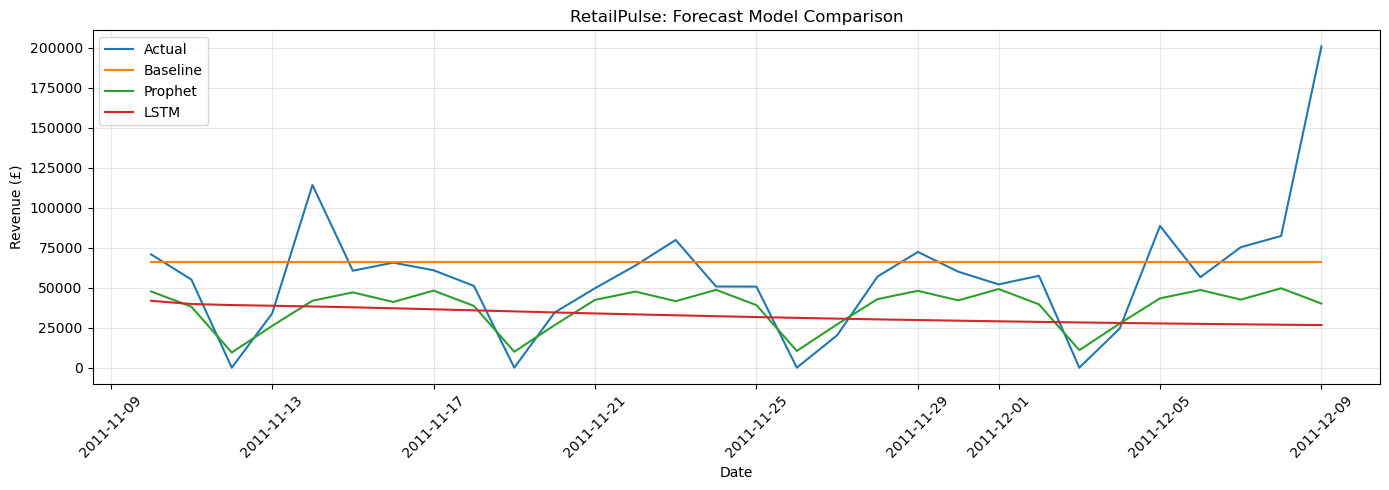

Model comparison saved: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\reports\model_comparison.csv
All predictions saved: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\reports\all_model_predictions.csv


In [24]:
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison metrics
results_df.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

# Save test predictions
final_predictions = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual_Revenue": y_true,
    "Naive_Forecast": baseline_pred,
    "Prophet_Forecast": prophet_pred,
    "LSTM_Forecast": lstm_predictions
})

final_predictions.to_csv(
    REPORTS_DIR / "all_model_predictions.csv",
    index=False
)

# Plot model comparison
plt.figure(figsize=(14, 5))
plt.plot(final_predictions["Date"], y_true, label="Actual")
plt.plot(final_predictions["Date"], baseline_pred, label="Baseline")
plt.plot(final_predictions["Date"], prophet_pred, label="Prophet")
plt.plot(final_predictions["Date"], lstm_predictions, label="LSTM")

plt.title("RetailPulse: Forecast Model Comparison")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Model comparison saved:", REPORTS_DIR / "model_comparison.csv")
print("All predictions saved:", REPORTS_DIR / "all_model_predictions.csv")

In [25]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
REPORTS_DIR = PROJECT_ROOT / "reports"

metrics = pd.read_csv(REPORTS_DIR / "model_comparison.csv")
predictions = pd.read_csv(REPORTS_DIR / "all_model_predictions.csv")

print("Model comparison shape:", metrics.shape)
print("Predictions shape:", predictions.shape)
print("\nModel comparison:")
print(metrics.to_string(index=False))
print("\nMissing values in predictions:")
print(predictions.isnull().sum())

Model comparison shape: (3, 4)
Predictions shape: (30, 5)

Model comparison:
         Model          MAE         RMSE  MAPE_percent
Naive Baseline 26741.022667 39349.326705     39.414582
       Prophet 22482.109350 37077.517911     30.486119
          LSTM 33832.610245 45821.509792     44.951702

Missing values in predictions:
Date                0
Actual_Revenue      0
Naive_Forecast      0
Prophet_Forecast    0
LSTM_Forecast       0
dtype: int64
